In [7]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
from urllib.parse import quote_plus
from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv()
engine = create_engine(
    f"mysql+pymysql://{os.getenv('MYSQL_USER')}:{quote_plus(os.getenv('MYSQL_PASSWORD'))}"
    f"@{os.getenv('MYSQL_HOST')}/{os.getenv('MYSQL_DB')}"
)

df = pd.read_sql("SELECT * FROM customers_features", engine)
X = df.drop(columns=["customerID", "Churn"])
model = joblib.load("../models/xgb_model.pkl")
print(X.shape)

(7043, 30)


In [8]:
explainer = shap.TreeExplainer(model)
shap_values = explainer(X)
print(shap_values.values.shape)   # (7043, number of features)

(7043, 30)


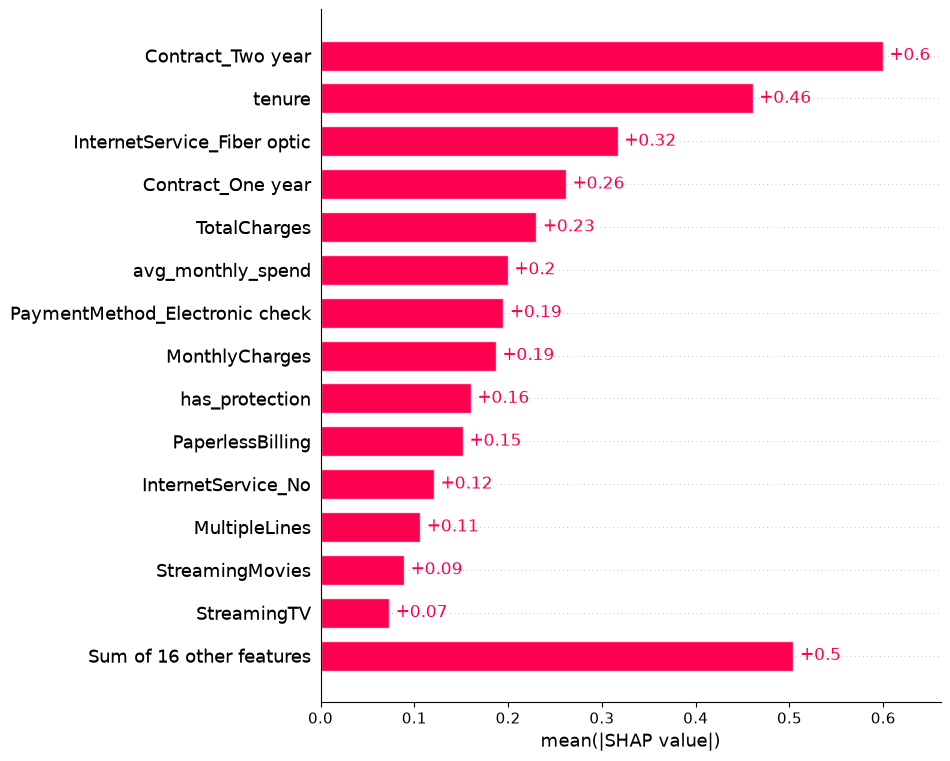

In [9]:
shap.plots.bar(shap_values, max_display=15)

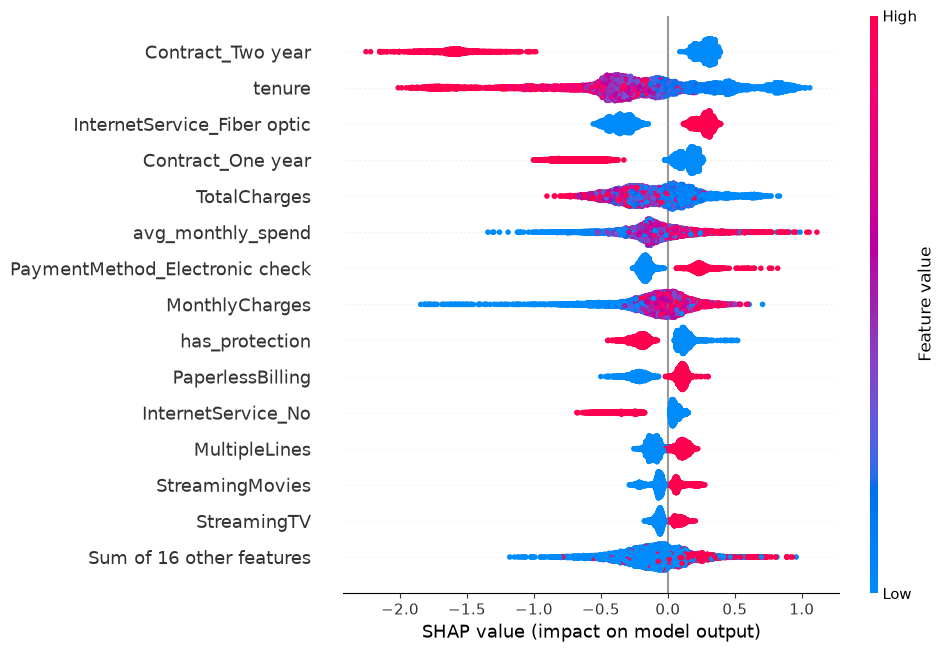

In [10]:
shap.plots.beeswarm(shap_values, max_display=15)

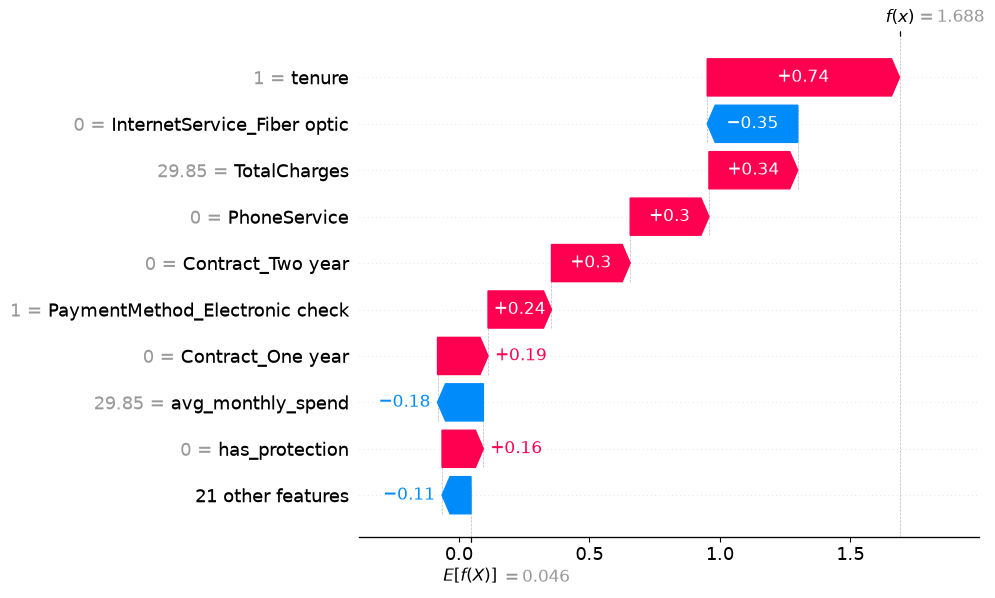

In [11]:
shap.plots.waterfall(shap_values[0])

In [12]:
importance = pd.DataFrame({
    "feature": X.columns,
    "mean_abs_shap": np.abs(shap_values.values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

importance.to_sql("shap_importance", engine, if_exists="replace", index=False)
importance.head(10)

,feature,mean_abs_shap
23,Contract_Two year,0.599575
4,tenure,0.460730
20,InternetService_Fiber optic,0.316875
22,Contract_One year,0.261701
15,TotalCharges,0.230018
19,avg_monthly_spend,0.199679
25,PaymentMethod_Electronic check,0.194926
14,MonthlyCharges,0.186902
18,has_protection,0.160225
13,PaperlessBilling,0.151854


In [13]:
vals = shap_values.values
top_idx = np.argsort(-vals, axis=1)[:, :3]
cols = np.array(X.columns)

drivers = pd.DataFrame({
    "customerID": df["customerID"],
    "top_churn_drivers": [", ".join(cols[i]) for i in top_idx]
})
drivers.to_sql("customer_churn_drivers", engine, if_exists="replace", index=False)
drivers.head()

,customerID,top_churn_drivers
0,7590-VHVEG,"tenure, TotalCharges, PhoneService"
1,5575-GNVDE,"Contract_Two year, InternetService_No, TechSup..."
2,3668-QPYBK,"tenure, TotalCharges, Contract_Two year"
3,7795-CFOCW,"Contract_Two year, PhoneService, MonthlyCharges"
4,9237-HQITU,"tenure, Contract_Two year, InternetService_Fib..."
